Stroke Prediction Using Logistic Regression - Jayden Batista - 10/29/2026

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    confusion_matrix,
    classification_report
)

from IPython.display import display

## 1. Load and Inspect the Dataset

In [2]:
# Load the dataset
df = pd.read_excel(r"C:\Users\Student\Downloads\Stroke_Prediction_Excel_Analysis_jaybat1453.xlsx", sheet_name='Patient Data')

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (15000, 34)

Column names:
['Patient ID', 'Patient Name', 'Age', 'Gender', 'Hypertension', 'Heart Disease', 'Marital Status', 'Work Type', 'Residence Type', 'Average Glucose Level', 'Body Mass Index (BMI)', 'Smoking Status', 'Alcohol Intake', 'Physical Activity', 'Stroke History', 'Family History of Stroke', 'Dietary Habits', 'Stress Levels', 'Systolic Blood Pressure', 'Diastolic Blood Pressure', 'HDL Cholesterol', 'LDL Cholesterol', 'Not Reported', 'Blurred Vision', 'Dizziness', 'Seizures', 'Weakness', 'Severe Fatigue', 'Headache', 'Confusion', 'Difficulty Speaking', 'Numbness', 'Loss of Balance', 'Diagnosis']

First five rows:


,Patient ID,Patient Name,Age,Gender,Hypertension,Heart Disease,Marital Status,Work Type,Residence Type,Average Glucose Level,...,Dizziness,Seizures,Weakness,Severe Fatigue,Headache,Confusion,Difficulty Speaking,Numbness,Loss of Balance,Diagnosis
0,18153,Mamooty Khurana,56,Male,0,1,Married,Self-employed,Rural,130.91,...,0,0,0,0,1,0,1,0,0,Stroke
1,62749,Kaira Subramaniam,80,Male,0,0,Single,Self-employed,Urban,183.73,...,1,0,0,0,1,1,0,0,1,Stroke
2,32145,Dhanush Balan,26,Male,1,1,Married,Never Worked,Rural,189.00,...,1,1,0,0,0,0,0,0,0,Stroke
3,6154,Ivana Baral,73,Male,0,0,Married,Never Worked,Urban,185.29,...,0,1,0,1,1,1,0,0,0,No Stroke
4,48973,Darshit Jayaraman,51,Male,1,1,Divorced,Self-employed,Urban,177.34,...,0,0,0,0,0,0,1,0,0,Stroke



Missing values:
Patient ID                  0
Patient Name                0
Age                         0
Gender                      0
Hypertension                0
Heart Disease               0
Marital Status              0
Work Type                   0
Residence Type              0
Average Glucose Level       0
Body Mass Index (BMI)       0
Smoking Status              0
Alcohol Intake              0
Physical Activity           0
Stroke History              0
Family History of Stroke    0
Dietary Habits              0
Stress Levels               0
Systolic Blood Pressure     0
Diastolic Blood Pressure    0
HDL Cholesterol             0
LDL Cholesterol             0
Not Reported                0
Blurred Vision              0
Dizziness                   0
Seizures                    0
Weakness                    0
Severe Fatigue              0
Headache                    0
Confusion                   0
Difficulty Speaking         0
Numbness                    0
Loss of Balance        

## 2. Prepare Target Variable and Features

In [3]:
# Identify the target column
target_column = "Diagnosis"

# Remove rows without a diagnosis
df = df.dropna(subset=[target_column]).copy()

# Convert diagnosis into binary values
# Stroke = 1, No Stroke = 0
diagnosis = (
    df[target_column]
    .astype(str)
    .str.strip()
    .str.casefold()
)

y = diagnosis.map({
    "stroke": 1,
    "no stroke": 0
})

if y.isna().any():
    unknown = diagnosis[y.isna()].unique()
    raise ValueError(f"Unexpected diagnosis values: {unknown}")

# Remove the target, identifier, and name columns from the predictors
# IMPORTANT: Patient Name must be excluded – otherwise one-hot encoding
# creates ~15,000 columns and causes memory errors.
exclude_columns = [
    target_column,
    "ID",
    "Patient ID",
    "Patient_ID",
    "PatientID",
    "Patient Name"          # <-- critical fix
]

X = df.drop(
    columns=[c for c in exclude_columns if c in df.columns]
).copy()

# Convert Boolean columns into categorical columns
for column in X.select_dtypes(include="bool").columns:
    X[column] = X[column].astype(str)

# Identify categorical columns
categorical_columns = X.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

print("Categorical columns that will be one-hot encoded:")
print(categorical_columns)

# Fill missing categorical values
for column in categorical_columns:
    X[column] = X[column].fillna("Unknown").astype(str)

# Fill missing numerical values with their medians
numeric_columns = X.select_dtypes(
    include="number"
).columns.tolist()

for column in numeric_columns:
    X[column] = X[column].fillna(X[column].median())

# One-hot encode categorical variables
X = pd.get_dummies(
    X,
    columns=categorical_columns,
    dtype=int
)

# Ensure all model inputs are numeric
X = X.astype(float)

print("\nNumber of features after encoding:", X.shape[1])
print("Encoded dataset shape:", X.shape)
display(X.head())


Categorical columns that will be one-hot encoded:
['Gender', 'Marital Status', 'Work Type', 'Residence Type', 'Smoking Status', 'Alcohol Intake', 'Physical Activity', 'Family History of Stroke', 'Dietary Habits']

Number of features after encoding: 52
Encoded dataset shape: (15000, 52)


,Age,Hypertension,Heart Disease,Average Glucose Level,Body Mass Index (BMI),Stroke History,Stress Levels,Systolic Blood Pressure,Diastolic Blood Pressure,HDL Cholesterol,...,Physical Activity_Moderate,Family History of Stroke_No,Family History of Stroke_Yes,Dietary Habits_Gluten-Free,Dietary Habits_Keto,Dietary Habits_Non-Vegetarian,Dietary Habits_Paleo,Dietary Habits_Pescatarian,Dietary Habits_Vegan,Dietary Habits_Vegetarian
0,56.0,0.0,1.0,130.91,22.37,0.0,3.48,140.0,108.0,68.0,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,80.0,0.0,0.0,183.73,32.57,0.0,1.73,146.0,91.0,63.0,...,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,26.0,1.0,1.0,189.00,20.32,0.0,7.31,154.0,97.0,59.0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,73.0,0.0,0.0,185.29,27.50,0.0,5.35,174.0,81.0,70.0,...,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,51.0,1.0,1.0,177.34,29.06,0.0,6.84,121.0,95.0,65.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


## 3. Train/Test Split and Scaling

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

# Standardize the features using training data only
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Data split and scaling completed.")

Training records: 12000
Testing records: 3000
Data split and scaling completed.


## 4. Train Logistic Regression Model

In [5]:
# Create the logistic regression model
model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

# Train the model
model.fit(X_train_scaled, y_train)

print("Logistic regression model trained successfully.")

Logistic regression model trained successfully.


## 5. Evaluate Model Performance

In [6]:
# Predict stroke diagnoses
y_pred = model.predict(X_test_scaled)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r_squared = r2_score(y_test, y_pred)

print("MODEL PERFORMANCE")
print("-----------------")
print(f"Accuracy:  {accuracy:.4f} ({accuracy:.2%})")
print(f"Precision: {precision:.4f} ({precision:.2%})")
print(f"Recall:    {recall:.4f} ({recall:.2%})")
print(f"MAE:       {mae:.4f}")
print(f"MSE:       {mse:.4f}")
print(f"R-squared: {r_squared:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Stroke", "Stroke"],
    zero_division=0
))

MODEL PERFORMANCE
-----------------
Accuracy:  0.5077 (50.77%)
Precision: 0.5059 (50.59%)
Recall:    0.4839 (48.39%)
MAE:       0.4923
MSE:       0.4923
R-squared: -0.9694

Confusion Matrix:
[[800 706]
 [771 723]]

Classification Report:
              precision    recall  f1-score   support

   No Stroke       0.51      0.53      0.52      1506
      Stroke       0.51      0.48      0.49      1494

    accuracy                           0.51      3000
   macro avg       0.51      0.51      0.51      3000
weighted avg       0.51      0.51      0.51      3000



## 6. Feature Importance

In [7]:
# Extract model coefficients
coefficients = model.coef_[0]

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": coefficients,
    "Absolute Importance": np.abs(coefficients)
})

# Sort from most important to least important
feature_importance = feature_importance.sort_values(
    by="Absolute Importance",
    ascending=False
).reset_index(drop=True)

print("TOP 15 FEATURES")
display(feature_importance.head(15))

# Show the strongest positive and negative predictors
print("\nStrongest positive predictors:")
display(
    feature_importance.sort_values(
        by="Coefficient",
        ascending=False
    ).head(10)
)

print("\nStrongest negative predictors:")
display(
    feature_importance.sort_values(
        by="Coefficient",
        ascending=True
    ).head(10)
)

TOP 15 FEATURES


,Feature,Coefficient,Absolute Importance
0,HDL Cholesterol,-0.046113,0.046113
1,Stress Levels,-0.037711,0.037711
2,Average Glucose Level,0.033169,0.033169
3,Hypertension,-0.028186,0.028186
4,Not Reported,-0.021578,0.021578
5,Marital Status_Married,0.020711,0.020711
6,Body Mass Index (BMI),-0.019227,0.019227
7,Dietary Habits_Paleo,0.018250,0.018250
8,Stroke History,-0.018061,0.018061
9,Smoking Status_Formerly Smoked,-0.017112,0.017112



Strongest positive predictors:


,Feature,Coefficient,Absolute Importance
2,Average Glucose Level,0.033169,0.033169
5,Marital Status_Married,0.020711,0.020711
7,Dietary Habits_Paleo,0.018250,0.018250
11,Family History of Stroke_No,0.015738,0.015738
13,Smoking Status_Currently Smokes,0.015641,0.015641
15,Dietary Habits_Keto,0.015058,0.015058
16,Alcohol Intake_Rarely,0.014045,0.014045
21,Physical Activity_Moderate,0.008989,0.008989
24,Numbness,0.008604,0.008604
26,Headache,0.008220,0.008220



Strongest negative predictors:


,Feature,Coefficient,Absolute Importance
0,HDL Cholesterol,-0.046113,0.046113
1,Stress Levels,-0.037711,0.037711
3,Hypertension,-0.028186,0.028186
4,Not Reported,-0.021578,0.021578
6,Body Mass Index (BMI),-0.019227,0.019227
8,Stroke History,-0.018061,0.018061
9,Smoking Status_Formerly Smoked,-0.017112,0.017112
10,Age,-0.015901,0.015901
12,Family History of Stroke_Yes,-0.015738,0.015738
14,Dietary Habits_Pescatarian,-0.015469,0.015469


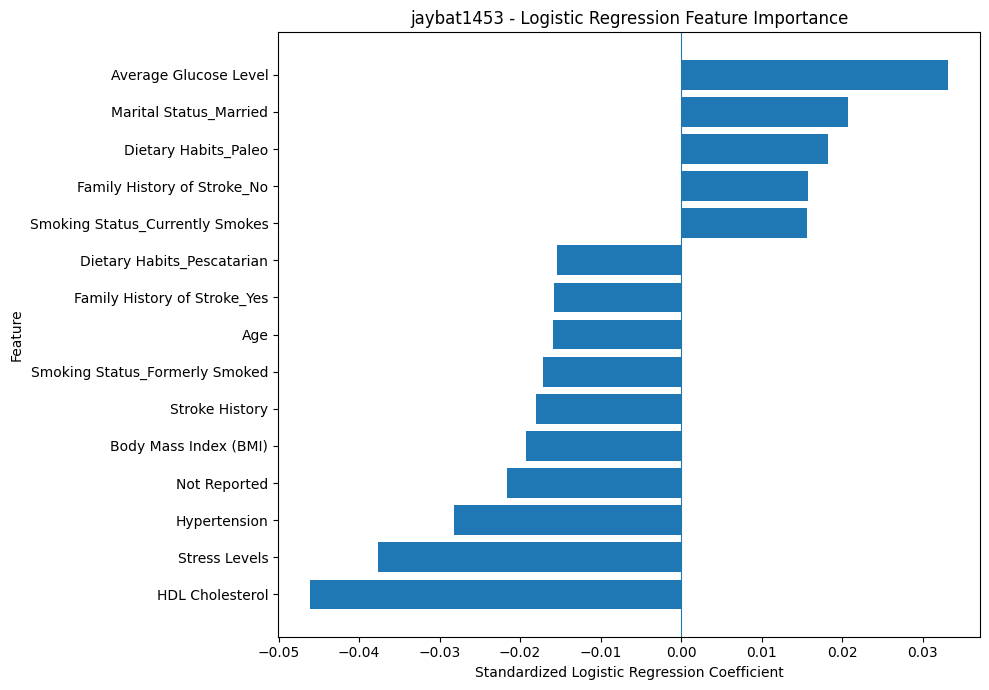

In [8]:
# Plot the top 15 features
top_features = feature_importance.head(15).sort_values(
    by="Coefficient"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)

plt.title("jaybat1453 - Logistic Regression Feature Importance")
plt.xlabel("Standardized Logistic Regression Coefficient")
plt.ylabel("Feature")
plt.axvline(0, linewidth=0.8)
plt.tight_layout()
plt.show()

## 7. BMI Analysis

In [9]:
# Find the BMI column
bmi_column = "Body Mass Index (BMI)"

if bmi_column in df.columns:
    bmi_values = pd.to_numeric(
        df[bmi_column],
        errors="coerce"
    ).dropna()

    bmi_25 = bmi_values.quantile(0.25)
    bmi_75 = bmi_values.quantile(0.75)

    # Find the corresponding encoded feature
    bmi_index = list(X.columns).index(bmi_column)

    # Use one testing record as the baseline
    baseline = X_test.iloc[[0]].copy()

    # Compare predictions at the 25th and 75th BMI percentiles
    lower_bmi = baseline.copy()
    higher_bmi = baseline.copy()

    lower_bmi.iloc[0, bmi_index] = bmi_25
    higher_bmi.iloc[0, bmi_index] = bmi_75

    # Scale using the previously fitted scaler
    lower_scaled = scaler.transform(lower_bmi)
    higher_scaled = scaler.transform(higher_bmi)

    lower_probability = model.predict_proba(
        lower_scaled
    )[0, 1]

    higher_probability = model.predict_proba(
        higher_scaled
    )[0, 1]

    bmi_coefficient = model.coef_[0][bmi_index]

    print("BMI ANALYSIS")
    print("------------")
    print(f"25th percentile BMI: {bmi_25:.2f}")
    print(f"75th percentile BMI: {bmi_75:.2f}")
    print(f"BMI coefficient: {bmi_coefficient:.4f}")
    print(
        f"Predicted stroke probability at lower BMI: "
        f"{lower_probability:.2%}"
    )
    print(
        f"Predicted stroke probability at higher BMI: "
        f"{higher_probability:.2%}"
    )
    print(
        f"Probability difference: "
        f"{higher_probability - lower_probability:+.2%}"
    )

else:
    print("The BMI column was not found. Check the dataset column names.")

BMI ANALYSIS
------------
25th percentile BMI: 21.16
75th percentile BMI: 33.72
BMI coefficient: -0.0192
Predicted stroke probability at lower BMI: 47.43%
Predicted stroke probability at higher BMI: 46.60%
Probability difference: -0.83%
